# Generate GIFs with magnetic-field labels

Run all cells to extract inputs when needed, produce and save 10 labeled GIFs, and preview the results. Each frame uses the corresponding value from `entry1/APD/magnetic_field` in its HDF5 file (units verified as mT). Both original and `_d` GIF variants retain their image content, frame order, and timing. Labels are added in a separate header above the image.

Dependencies: `h5py`, `numpy`, `pillow`, `matplotlib`, and `ipython`. If needed, run `%pip install h5py numpy pillow matplotlib ipython`.

In [ ]:
from pathlib import Path
import subprocess
import base64
from html import escape
import h5py
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from IPython.display import HTML, display

project_dir = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "raw" / "images").is_dir() or (p / "raw" / "2026-11-06.rar").exists()), None)
if project_dir is None:
    raise FileNotFoundError("Set project_dir to the project containing raw/images/.")
image_dir = project_dir / "raw" / "images"
data_dir = project_dir / "raw" / "data"
output_dir = project_dir / "output" / "labeled_gifs"
for directory in (image_dir, data_dir, output_dir):
    directory.mkdir(parents=True, exist_ok=True)

# bsdtar supports this RAR archive on macOS. Extract only missing inputs.
archive = project_dir / "raw" / "2026-11-06.rar"
if archive.exists():
    members = subprocess.check_output(["bsdtar", "-tf", str(archive)], text=True).splitlines()
    for suffix, destination in [(".gif", image_dir), (".hdf5", data_dir)]:
        missing = [name for name in members if name.endswith(suffix)
                   and not (destination / name).exists()]
        if missing:
            subprocess.run(["bsdtar", "-xf", str(archive), "-C", str(destination), *missing], check=True)
gif_paths = sorted(image_dir.glob("Sample_Stack_*.gif"))
if not gif_paths:
    raise FileNotFoundError("No source GIFs found.")
print(f"Found {len(gif_paths)} input GIFs. Output: {output_dir}")
from matplotlib.colors import Normalize, LogNorm
from tqdm.auto import tqdm
# A matching HDF5 file supplies the field labels for each source GIF.
missing_metadata = [p for p in gif_paths if not (data_dir / f"{p.stem.removesuffix('_d')}.hdf5").exists()]
for path in missing_metadata:
    print(f"Skipping {path.name}: matching HDF5 field metadata is missing")
gif_paths = [p for p in gif_paths if p not in missing_metadata]


In [2]:
# Increase display size for the small 100 x 100 pixel images.
minimum_image_width = 400
header_height = 46
font = ImageFont.load_default(size=20)


def save_labeled_gif(source, destination):
    stem = source.stem.removesuffix("_d")
    with h5py.File(data_dir / f"{stem}.hdf5", "r") as h5:
        field_dataset = h5["entry1/APD/magnetic_field"]
        units = field_dataset.attrs.get("units", "")
        if isinstance(units, bytes):
            units = units.decode()
        if units != "mT":
            raise ValueError(f"Unexpected magnetic-field units: {units!r}")
        fields = np.asarray(field_dataset[()], dtype=float).reshape(-1)
    if not np.all(np.isfinite(fields)):
        raise ValueError(f"Non-finite magnetic fields for {source.name}")

    frames, durations = [], []
    with Image.open(source) as gif:
        if gif.n_frames != len(fields):
            raise ValueError(f"{source.name}: {gif.n_frames} frames vs {len(fields)} field values")
        for index, field in enumerate(fields):
            gif.seek(index)
            image = gif.convert("RGB")
            scale = max(1, int(np.ceil(minimum_image_width / image.width)))
            image = image.resize((image.width * scale, image.height * scale), Image.Resampling.NEAREST)
            canvas = Image.new("RGB", (image.width, image.height + header_height), "white")
            canvas.paste(image, (0, header_height))
            ImageDraw.Draw(canvas).text(
                (12, 10), f"B = {field:+g} mT   |   {index + 1}/{len(fields)}",
                font=font, fill="black")
            frames.append(canvas)
            durations.append(gif.info.get("duration", 100))
    frames[0].save(destination, save_all=True, append_images=frames[1:],
                   duration=durations, loop=0, disposal=2, optimize=False)
    # Reopen the saved file to verify that all labeled frames and timings survived.
    with Image.open(destination) as saved:
        assert saved.n_frames == len(fields), destination.name
        for index, duration in enumerate(durations):
            saved.seek(index)
            assert saved.info["duration"] == duration, (destination.name, index)
    return len(fields), float(fields.min()), float(fields.max())


saved_paths = []
for source in gif_paths:
    destination = output_dir / f"{source.stem}_labeled.gif"
    count, low, high = save_labeled_gif(source, destination)
    saved_paths.append(destination)
    print(f"Saved {destination.name}: {count} frames, {low:g} to {high:g} mT")

Saved Sample_Stack_2026-11-06_069_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_069_d_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_078_labeled.gif: 51 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_078_d_labeled.gif: 51 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_079_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_079_d_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_080_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_080_d_labeled.gif: 21 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_082_labeled.gif: 126 frames, -250 to 250 mT
Saved Sample_Stack_2026-11-06_082_d_labeled.gif: 126 frames, -250 to 250 mT


## Plot a selected frame
Change `frame_index` to inspect a different frame. Shorter GIFs use their last frame.

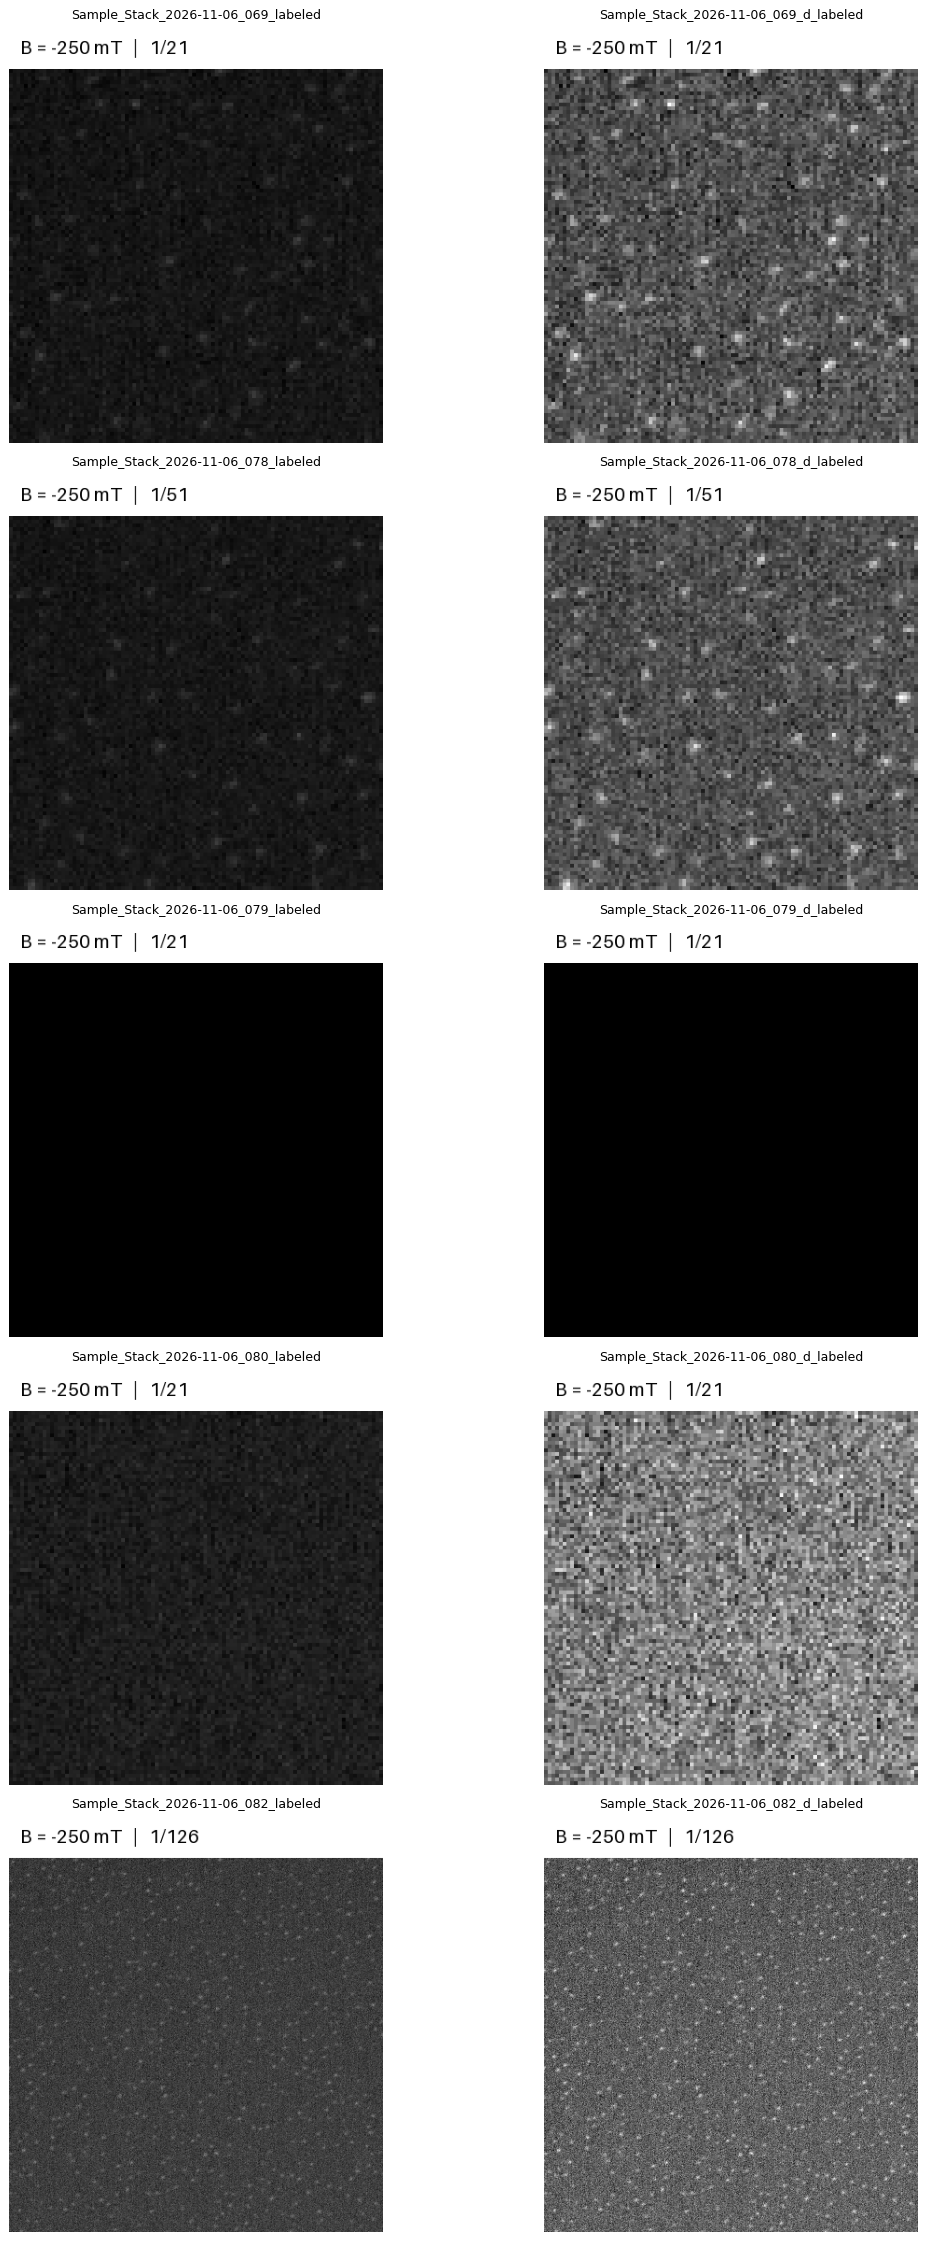

In [3]:
frame_index = 0
if frame_index < 0:
    raise ValueError("frame_index must be nonnegative")
fig, axes = plt.subplots((len(saved_paths) + 1) // 2, 2, figsize=(14, 25), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, path in zip(axes.flat, saved_paths):
    with Image.open(path) as gif:
        gif.seek(min(frame_index, gif.n_frames - 1))
        ax.imshow(gif.convert("RGB"))
    ax.set_title(path.stem, fontsize=10)
fig.tight_layout()
plt.show()

## Saved animations
The animations below are embedded in the notebook; the GIF files are also saved in `output/labeled_gifs/`.

In [4]:
cards = []
for path in saved_paths:
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    cards.append(f'<figure style="margin:0;padding:12px;border:1px solid #bbb">'
                 f'<figcaption>{escape(path.name)}</figcaption>'
                 f'<img src="data:image/gif;base64,{encoded}" '
                 f'style="width:100%;max-height:550px;object-fit:contain" /></figure>')
display(HTML('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px">'
             + "".join(cards) + '</div>'))

<IPython.core.display.HTML object>


## Fourier power images and animations
Compute `abs(fftshift(fft2(image)))**2` from each original grayscale GIF frame before adding labels. Zero frequency is centered; the DC component is retained.

Both linear and logarithmic versions are saved. Scale limits exclude a central disk of radius 3 frequency pixels. Linear display runs from zero to the 99.5th percentile; log display uses the 1st–99.5th percentiles of positive power. Each scale is fixed across its animation. The center remains visible and can saturate. Colorbars show Fourier power, with logarithmic normalization for log versions; zero-power pixels are masked in the log display.

GIFs are saved in `output/fourier_gifs/`. Selected-frame PNGs (using `frame_index` above) are saved in `output/fourier_images/`. Field labels, frame order and durations are preserved. These are transforms of GIF intensities, not raw detector counts.

In [ ]:
fourier_dir = project_dir / "output" / "fourier_gifs"
fourier_dir.mkdir(parents=True, exist_ok=True)
fourier_image_dir = project_dir / "output" / "fourier_images"
fourier_image_dir.mkdir(parents=True, exist_ok=True)


def save_fourier_gif(source, destination, log_scale=False):
    stem = source.stem.removesuffix("_d")
    with h5py.File(data_dir / f"{stem}.hdf5", "r") as h5:
        dataset = h5["entry1/APD/magnetic_field"]
        units = dataset.attrs.get("units", "")
        if isinstance(units, bytes):
            units = units.decode()
        if units != "mT":
            raise ValueError(f"Unexpected magnetic-field units: {units!r}")
        fields = np.asarray(dataset[()], dtype=float).reshape(-1)
    if not np.all(np.isfinite(fields)):
        raise ValueError(f"Non-finite magnetic fields for {source.name}")

    powers, durations = [], []
    with Image.open(source) as gif:
        loop = gif.info.get("loop", 0)
        if gif.n_frames != len(fields):
            raise ValueError(f"{source.name}: {gif.n_frames} frames vs {len(fields)} field values")
        for index in range(gif.n_frames):
            gif.seek(index)
            # Transform source pixels before adding labels or enlarging the image.
            pixels = np.asarray(gif.convert("L"), dtype=np.float64)
            power = np.abs(np.fft.fftshift(np.fft.fft2(pixels))) ** 2
            powers.append(power)
            durations.append(gif.info.get("duration", 100))

    # Fixed limits across frames, ignoring the intense center when choosing them.
    power_stack = np.stack(powers)
    height, width = power_stack.shape[1:]
    yy, xx = np.ogrid[:height, :width]
    outside_center = (yy - height // 2) ** 2 + (xx - width // 2) ** 2 > 3 ** 2
    values = power_stack[:, outside_center]
    if log_scale:
        positive = values[values > 0]
        vmin, vmax = np.percentile(positive, [1, 99.5]) if positive.size else (1, 10)
        norm = LogNorm(vmin=vmin, vmax=max(vmax, vmin * 1.01), clip=True)
    else:
        vmax = float(np.percentile(values, 99.5)) if values.size else 1.0
        norm = Normalize(vmin=0, vmax=max(vmax, 1e-12), clip=True)
    scale_name = "log" if log_scale else "linear"
    fig, ax = plt.subplots(figsize=(7, 6), dpi=100, constrained_layout=True)
    artist = ax.imshow(power_stack[0], origin="lower", cmap="magma", norm=norm,
                       interpolation="nearest")
    ax.set(xlabel="Horizontal frequency bin (shifted)", ylabel="Vertical frequency bin (shifted)")
    fig.colorbar(artist, ax=ax, label=f"|FT(image)|² ({scale_name} scale)")
    selected_index = min(frame_index, len(fields) - 1)
    frames = []
    for index, (field, power) in enumerate(zip(fields, power_stack)):
        shown = np.ma.masked_less_equal(power, 0) if log_scale else power
        artist.set_data(shown)
        ax.set_title(f"{source.stem}\nB = {field:+g} mT | {index + 1}/{len(fields)} | {scale_name}")
        if index == selected_index:
            fig.savefig(fourier_image_dir / f"{source.stem}_fourier_power_{scale_name}_frame_{index:03d}.png",
                        dpi=150)
        fig.canvas.draw()
        frame = Image.fromarray(np.asarray(fig.canvas.buffer_rgba()).copy()).convert("RGB")
        frames.append(frame)
    plt.close(fig)
    frames[0].save(destination, save_all=True, append_images=frames[1:],
                   duration=durations, loop=loop, disposal=2, optimize=False)
    with Image.open(destination) as saved:
        assert saved.n_frames == len(fields), destination.name
        for index, duration in enumerate(durations):
            saved.seek(index)
            assert saved.info["duration"] == duration, (destination.name, index)
    return len(fields)


fourier_paths = []
fourier_log_paths = []
for source in tqdm(gif_paths, desc="STXM Fourier GIFs", unit="source"):
    destination = fourier_dir / f"{source.stem}_fourier_power.gif"
    count = save_fourier_gif(source, destination)
    fourier_paths.append(destination)
    log_destination = fourier_dir / f"{source.stem}_fourier_power_log.gif"
    save_fourier_gif(source, log_destination, log_scale=True)
    fourier_log_paths.append(log_destination)
    print(f"Saved linear and log Fourier GIFs: {source.stem} ({count} frames)")


In [ ]:
fourier_cards = []
for path in [*fourier_paths, *fourier_log_paths]:
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    fourier_cards.append(f'<figure style="margin:0;padding:12px;border:1px solid #bbb">'
                         f'<figcaption>{escape(path.name)}</figcaption>'
                         f'<img src="data:image/gif;base64,{encoded}" '
                         f'style="width:100%;max-height:550px;object-fit:contain" /></figure>')
display(HTML('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px">'
             + "".join(fourier_cards) + '</div>'))


## Selected Fourier images
Linear and log versions of the selected `frame_index`, each with a colorbar.

In [ ]:
image_cards = []
for source in gif_paths:
    with Image.open(source) as gif:
        index = min(frame_index, gif.n_frames - 1)
    for scale_name in ("linear", "log"):
        path = fourier_image_dir / f"{source.stem}_fourier_power_{scale_name}_frame_{index:03d}.png"
        encoded = base64.b64encode(path.read_bytes()).decode("ascii")
        image_cards.append(f'<figure><figcaption>{escape(path.name)}</figcaption>'
                           f'<img src="data:image/png;base64,{encoded}" style="width:100%"></figure>')
display(HTML('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr))">'
             + ''.join(image_cards) + '</div>'))